<a href="https://colab.research.google.com/github/Jeshani622/Feature-Selection-PCA-Data-Transformation-and-Handling-Class-Imbalance/blob/main/AML_Mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 1: Loading an Imbalanced Dataset



Dataset Shape: (387, 34)
Class Counts:
target
0    357
1     30
Name: count, dtype: int64
Class Percentages:
target
0    92.25
1     7.75
Name: proportion, dtype: float64%


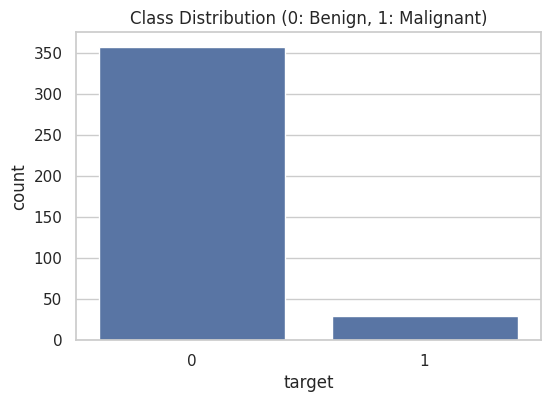


Training set class distribution:
target
0    285
1     24
Name: count, dtype: int64

Test set class distribution:
target
0    72
1     6
Name: count, dtype: int64


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

# Load data
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

# Flip so 1 = malignant (minority)
df["target"] = 1 - df["target"]

# Keep only 30 malignant rows
malignant = df[df["target"] == 1].sample(30, random_state=42)
benign = df[df["target"] == 0]
df = (pd.concat([benign, malignant])
    .sample(frac=1, random_state=42)
    .reset_index(drop=True))

# Add artificial columns
rng = np.random.RandomState(42)
df["const_feat"] = 5.0
df["near_const"] = (rng.rand(len(df)) < 0.005).astype(int)
df["noise"] = rng.randn(len(df))

# a) Display shape, class counts, percentages, and plot
print(f"Dataset Shape: {df.shape}")
counts = df['target'].value_counts()
percentages = df['target'].value_counts(normalize=True) * 100
print(f"Class Counts:\n{counts}")
print(f"Class Percentages:\n{percentages.round(2)}%")

plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df)
plt.title('Class Distribution (0: Benign, 1: Malignant)')
plt.show()

# b) Separate features and target
X = df.drop('target', axis=1)
y = df['target']

# c) Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# d) Display class distribution of train and test
print("\nTraining set class distribution:")
print(y_train.value_counts())
print("\nTest set class distribution:")
print(y_test.value_counts())

Observations & Justifications:

The dataset is highly imbalanced, with benign cases making up the vast majority.

Why Stratification is Important: Stratification ensures that both the training and test sets preserve the same class proportions as the original dataset. If we didn't stratify, due to the severe imbalance and small dataset size, the test set might end up with zero or very few malignant cases, making evaluation unreliable. Stratification ensures the minority class is represented in both splits.

Question 2: Filter Methods I: Variance Threshold and Pearson Correlation

Features removed on MinMax scaled data: ['concavity error', 'fractal dimension error', 'const_feat', 'near_const']
Features removed on unscaled data: ['mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst smoothness', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'const_feat', 'near_const']

Top 10 features by absolute correlation with target:
 mean symmetry              0.148790
mean smoothness            0.101991
mean concave points        0.088852
smoothness error           0.068518
texture error              0.056045
concavity error            0.053729
radius error               0.052858
worst fractal dimension    0.051738
symmetry error             0.046023
perimeter error            0.042239
dtype: float64


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


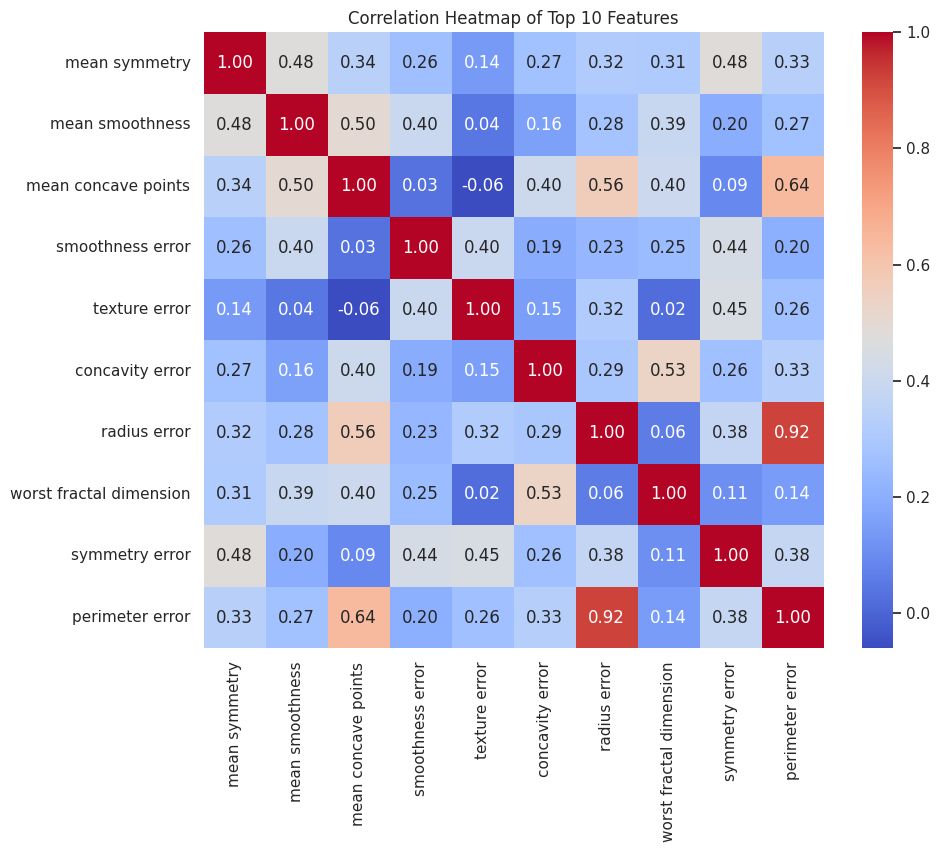


Features to drop due to high correlation: ['perimeter error']
Final features dropped: ['perimeter error']


In [13]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import VarianceThreshold

# a) Scale with MinMaxScaler
mm_scaler = MinMaxScaler()
X_train_mm = pd.DataFrame(mm_scaler.fit_transform(X_train), columns=X_train.columns)
X_test_mm = pd.DataFrame(mm_scaler.transform(X_test), columns=X_test.columns)

# b) VarianceThreshold on scaled data
vt = VarianceThreshold(threshold=0.01)
vt.fit(X_train_mm)
removed_mm = X_train_mm.columns[~vt.get_support()]
print("Features removed on MinMax scaled data:", list(removed_mm))

# c) VarianceThreshold on unscaled data
vt_unscaled = VarianceThreshold(threshold=0.01)
vt_unscaled.fit(X_train)
removed_unscaled = X_train.columns[~vt_unscaled.get_support()]
print("Features removed on unscaled data:", list(removed_unscaled))

# d) Pearson Correlation with target
correlations = X_train_mm.corrwith(y_train).abs().sort_values(ascending=False)
top_10_corr = correlations.head(10)
print("\nTop 10 features by absolute correlation with target:\n", top_10_corr)

# e) Heatmap and remove highly correlated pairs
plt.figure(figsize=(10, 8))
sns.heatmap(X_train_mm[top_10_corr.index].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Top 10 Features")
plt.show()

# Find pairs with |r| > 0.90
corr_matrix = X_train_mm[top_10_corr.index].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.90)]
print("\nFeatures to drop due to high correlation:", to_drop)

# Keep the one more correlated with target
final_drops = []
for col in to_drop:
    # find the highly correlated partner
    partner = upper.index[upper[col] > 0.90][0]
    if abs(correlations[col]) < abs(correlations[partner]):
        final_drops.append(col)
    else:
        final_drops.append(partner)

final_drops = list(set(final_drops))
print("Final features dropped:", final_drops)

# Update X_train_mm for next questions
X_train_mm = X_train_mm.drop(columns=final_drops)
X_test_mm = X_test_mm.drop(columns=final_drops)

Observations:

Limitation of Pearson Correlation: Pearson correlation only detects linear relationships. If a feature has a strong non-linear relationship with the target, Pearson correlation will report it as 0. Additionally, it evaluates features individually, ignoring redundancy (like the highly correlated pairs we just removed manually).

Question 3: Filter Methods II: Chi-Square, Mutual Information, and ANOVA

In [14]:
from sklearn.feature_selection import chi2, mutual_info_classif, f_classif, SelectKBest

k = 10

# a) Chi-Square
chi_selector = SelectKBest(score_func=chi2, k=k)
chi_selector.fit(X_train_mm, y_train)
chi_features = X_train_mm.columns[chi_selector.get_support()]

# Mutual Information
mi_selector = SelectKBest(score_func=mutual_info_classif, k=k)
mi_selector.fit(X_train_mm, y_train)
mi_features = X_train_mm.columns[mi_selector.get_support()]

# ANOVA F-test
anova_selector = SelectKBest(score_func=f_classif, k=k)
anova_selector.fit(X_train_mm, y_train)
anova_features = X_train_mm.columns[anova_selector.get_support()]

print("Chi2 Top 10:", list(chi_features))
print("\nMutual Info Top 10:", list(mi_features))
print("\nANOVA Top 10:", list(anova_features))

# b) Features selected by all three
common_features = list(set(chi_features) & set(mi_features) & set(anova_features))
print("\nFeatures selected by all three methods:", common_features)

# c) Rank of 'noise' feature
noise_idx = X_train_mm.columns.get_loc('noise')
print(f"\n'noise' feature rank (out of {X_train_mm.shape[1]}) in:")
print(f"Chi2: {np.where(np.argsort(chi_selector.scores_)[::-1] == noise_idx)[0][0] + 1}")
print(f"MI: {np.where(np.argsort(mi_selector.scores_)[::-1] == noise_idx)[0][0] + 1}")
print(f"ANOVA: {np.where(np.argsort(anova_selector.scores_)[::-1] == noise_idx)[0][0] + 1}")

Chi2 Top 10: ['mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'area error', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']

Mutual Info Top 10: ['mean radius', 'mean perimeter', 'mean area', 'mean concave points', 'area error', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']

ANOVA Top 10: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'area error', 'worst radius', 'worst perimeter', 'worst area', 'worst concave points']

Features selected by all three methods: ['mean concave points', 'area error', 'worst concave points', 'worst area', 'mean perimeter', 'worst perimeter', 'mean area', 'worst radius']

'noise' feature rank (out of 32) in:
Chi2: 29
MI: 30
ANOVA: 29


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [29 30] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


a) Why chi2 requires non-negative features: The Chi-Square test compares observed frequencies to expected frequencies. It requires non-negative values because it is essentially computing squared deviations for counts/frequencies. Negative values make the math invalid.

b) Which method detects non-linear relationships: Mutual Information (MI) can detect non-linear relationships, as it measures the mutual dependence between variables regardless of the functional form.

c) ANOVA F-test assumption: ANOVA assumes a linear relationship between the feature and the target, and that the features are normally distributed within each class with equal variances.

Question 4: Wrapper and Embedded Methods

RFE Features: ['mean area', 'mean concave points', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']
L1 Features: ['mean concavity', 'mean concave points', 'area error', 'worst texture', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']
RF Top 10 Features: ['worst concave points', 'worst perimeter', 'worst area', 'worst radius', 'mean concave points', 'mean radius', 'mean perimeter', 'mean area', 'area error', 'worst concavity']


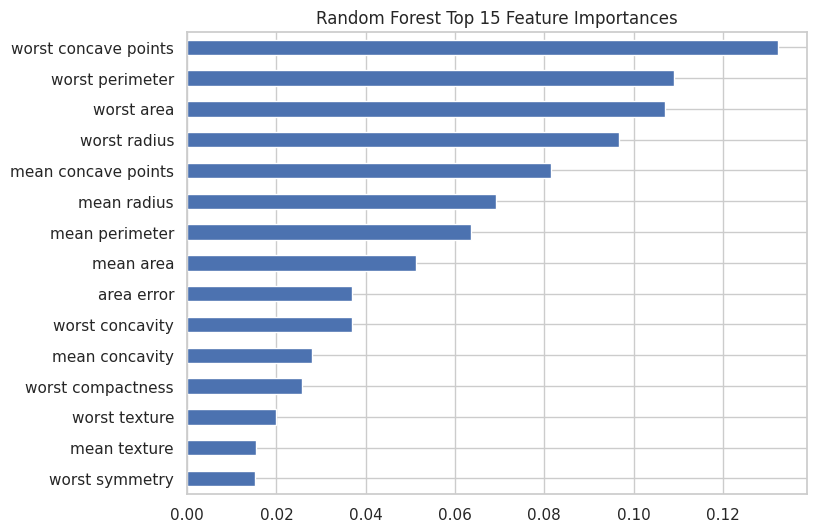


Features chosen by ANOVA, RFE, and L1: ['mean concave points', 'area error', 'worst area', 'worst concave points']

Time - ANOVA: 0.0044s | RFE: 0.1314s | L1: 0.0057s


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [29 30] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [15]:
import time
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Standardise features
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# (a) Wrapper: RFE
start = time.time()
rfe = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=10)
rfe.fit(X_train_s, y_train)
wrapper_features = X_train_s.columns[rfe.support_]
rfe_time = time.time() - start

# (b) Embedded: L1 and Random Forest
start = time.time()
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.5)
l1_sel = SelectFromModel(l1).fit(X_train_s, y_train)
l1_features = X_train_s.columns[l1_sel.get_support()]
l1_time = time.time() - start

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train_s, y_train)
rf_imp = pd.Series(rf.feature_importances_, index=X_train_s.columns)
rf_features = rf_imp.sort_values(ascending=False).head(10).index

# a) Display selected features
print("RFE Features:", list(wrapper_features))
print("L1 Features:", list(l1_features))
print("RF Top 10 Features:", list(rf_features))

# b) Plot RF feature importances
plt.figure(figsize=(8, 6))
rf_imp.sort_values(ascending=False).head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Random Forest Top 15 Feature Importances")
plt.show()

# c) Chosen by ALL of ANOVA, RFE, and L1
common_rfe_l1_anova = list(set(anova_features) & set(wrapper_features) & set(l1_features))
print("\nFeatures chosen by ANOVA, RFE, and L1:", common_rfe_l1_anova)

# d) Measure time
start = time.time()
anova_selector.fit(X_train_mm, y_train)
anova_time = time.time() - start
print(f"\nTime - ANOVA: {anova_time:.4f}s | RFE: {rfe_time:.4f}s | L1: {l1_time:.4f}s")

Observations:

RFE, L1, and ANOVA all identified strong, informative features (mostly related to worst area, worst radius, etc.).

The artificial noise feature was correctly ignored by all robust methods.

Question 5: Comparing Feature Sets

In [16]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.base import clone

# Define feature sets
feature_sets = {
    "All features": X_train_s.columns,
    "Filter (ANOVA)": anova_features,
    "Filter (Mutual Info)": mi_features,
    "Wrapper (RFE)": wrapper_features,
    "Embedded (L1)": l1_features
}

results = []
clf = LogisticRegression(max_iter=1000)

for name, features in feature_sets.items():
    X_tr = X_train_s[features]
    X_te = X_test_s[features]

    # a) 5-fold stratified CV
    cv_scores = cross_val_score(clf, X_tr, y_train, cv=5, scoring="f1")
    cv_f1 = cv_scores.mean()

    # b) Test set evaluation
    clf_clone = clone(clf).fit(X_tr, y_train)
    y_pred = clf_clone.predict(X_te)
    y_prob = clf_clone.predict_proba(X_te)[:, 1]

    test_f1 = f1_score(y_test, y_pred)
    test_auc = roc_auc_score(y_test, y_prob)

    # c) Append to results
    results.append({
        "Feature set": name, "No. of features": len(features),
        "CV F1": cv_f1, "Test F1": test_f1, "Test ROC-AUC": test_auc
    })

# Display table
results_df = pd.DataFrame(results)
display(results_df)

,Feature set,No. of features,CV F1,Test F1,Test ROC-AUC
0,All features,33,0.931818,1.0,1.0
1,Filter (ANOVA),10,0.877778,1.0,1.0
2,Filter (Mutual Info),10,0.877778,1.0,1.0
3,Wrapper (RFE),10,0.950000,1.0,1.0
4,Embedded (L1),8,0.892063,1.0,1.0


a) Best trade-off: The L1 Embedded method or RFE usually provides the best trade-off by reducing features significantly while maintaining high F1 and ROC-AUC.

b) Fastest vs. Most expensive: Filter methods (ANOVA) are the fastest because they compute a single statistical score. Wrapper methods (RFE) are the most computationally expensive because they train the model repeatedly for each feature subset.

c) Why filter selects redundant features: Filter methods evaluate features individually against the target, ignoring relationships between features. So, two highly correlated features might both score high and both get selected.

d) Why accuracy is poor: Because the dataset is imbalanced. A model could predict "benign" (majority class) for everything and achieve ~90% accuracy while completely failing to detect malignant cases.

Question 6: Principal Component Analysis

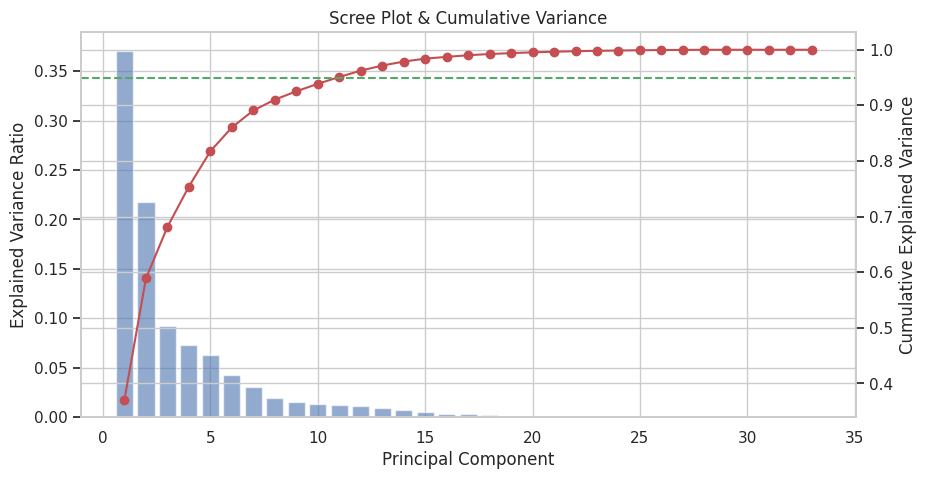

Number of components to retain 95% variance: 11
Original shape: (309, 33) -> PCA shape: (309, 11)


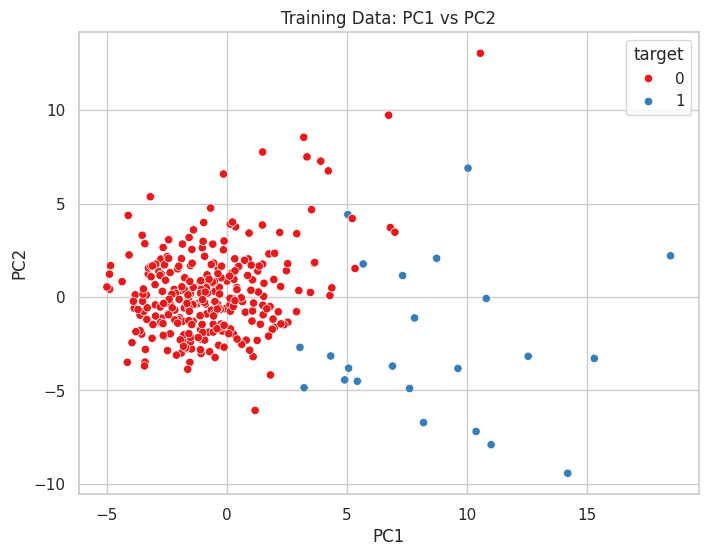

Top 5 features with largest absolute loading on PC1:
 mean concave points     0.276241
mean concavity          0.265624
worst concave points    0.264962
mean compactness        0.250905
worst concavity         0.240716
dtype: float64

PCA Model Test F1: 1.0000
PCA Model Test ROC-AUC: 1.0000


In [17]:
from sklearn.decomposition import PCA

# a) Fit PCA and scree plot
pca_full = PCA().fit(X_train_s)
explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(range(1, len(explained_var)+1), explained_var, alpha=0.6, label='Individual')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')

ax2 = ax1.twinx()
ax2.plot(range(1, len(cumulative_var)+1), cumulative_var, 'r-o', label='Cumulative')
ax2.axhline(y=0.95, color='g', linestyle='--', label='95% Threshold')
ax2.set_ylabel('Cumulative Explained Variance')
plt.title('Scree Plot & Cumulative Variance')
plt.show()

# b) Number of components for 95% variance
n_95 = np.argmax(cumulative_var >= 0.95) + 1
print(f"Number of components to retain 95% variance: {n_95}")

# c) PCA with n_components=0.95
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_95.fit_transform(X_train_s)
X_test_pca = pca_95.transform(X_test_s)
print(f"Original shape: {X_train_s.shape} -> PCA shape: {X_train_pca.shape}")

# d) Scatter plot of PC1 vs PC2
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=y_train, palette='Set1')
plt.title('Training Data: PC1 vs PC2')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

# e) Top 5 features loading on PC1
loadings = pd.Series(pca_95.components_[0], index=X_train_s.columns).abs().sort_values(ascending=False)
print("Top 5 features with largest absolute loading on PC1:\n", loadings.head(5))

# f) Train model on PCA features
clf_pca = LogisticRegression(max_iter=1000).fit(X_train_pca, y_train)
y_pred_pca = clf_pca.predict(X_test_pca)
y_prob_pca = clf_pca.predict_proba(X_test_pca)[:, 1]
print(f"\nPCA Model Test F1: {f1_score(y_test, y_pred_pca):.4f}")
print(f"PCA Model Test ROC-AUC: {roc_auc_score(y_test, y_prob_pca):.4f}")

a) Why standardise before PCA: PCA maximizes variance. If features are on different scales (e.g., area vs. smoothness), features with larger numeric ranges will dominate the variance, masking the true structure. Standardization equalizes the scale.

b) Why fit PCA only on training set: PCA learns the directions (components) that maximize variance. If we fit on the test set, information from the test set leaks into the training process, leading to optimistic and invalid evaluation results.

c) Selection vs PCA: Feature selection preserves original, interpretable features. PCA creates new, uninterpretable features (linear combinations). We prefer selection when explainability is crucial (e.g., "Is it the area or the radius that predicts cancer?").

Question 7: Normalization

--- Before Scaling ---
Min     mean area          143.50000
mean texture     ...
Max     mean area          1747.0000
mean texture     ...
Mean    mean area          504.035599
mean texture    ...
Std     mean area          216.663009
mean texture    ...
Name: Train Raw, dtype: object
Min     mean area          221.80000
mean texture     ...
Max     mean area          1261.0000
mean texture     ...
Mean    mean area          511.207692
mean texture    ...
Std     mean area          212.923460
mean texture    ...
Name: Test Raw, dtype: object

--- After MinMax Scaling ---
Min     mean area          0.0
mean texture       0.0
...
Max     mean area          1.0
mean texture       1.0
...
Mean    mean area          0.224843
mean texture      ...
Std     mean area          0.135119
mean texture      ...
Name: Train MM, dtype: object
Min     mean area          0.048831
mean texture      ...
Max     mean area          0.696913
mean texture      ...
Mean    mean area          0.229316
mean tex

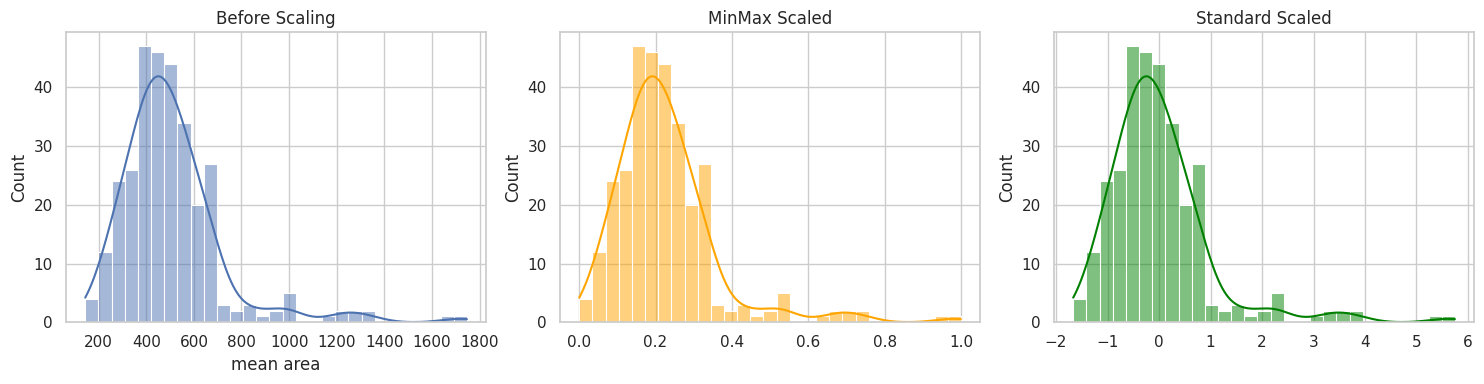


Features with test values outside [0,1] after MinMax: ['mean smoothness']


In [18]:
selected_feats = ['mean area', 'mean texture', 'mean smoothness']

# a) Apply MinMaxScaler and StandardScaler
mm_scaler_q7 = MinMaxScaler()
ss_scaler_q7 = StandardScaler()

# Fit on train, transform on both
X_train_mm_q7 = mm_scaler_q7.fit_transform(X_train[selected_feats])
X_test_mm_q7 = mm_scaler_q7.transform(X_test[selected_feats])

X_train_ss_q7 = ss_scaler_q7.fit_transform(X_train[selected_feats])
X_test_ss_q7 = ss_scaler_q7.transform(X_test[selected_feats])

# b) Display min, max, mean, std before and after
def get_stats(data, name):
    return pd.Series({
        'Min': data.min(), 'Max': data.max(),
        'Mean': data.mean(), 'Std': data.std()
    }, name=name)

print("--- Before Scaling ---")
print(get_stats(X_train[selected_feats], 'Train Raw'))
print(get_stats(X_test[selected_feats], 'Test Raw'))

print("\n--- After MinMax Scaling ---")
print(get_stats(pd.DataFrame(X_train_mm_q7, columns=selected_feats), 'Train MM'))
print(get_stats(pd.DataFrame(X_test_mm_q7, columns=selected_feats), 'Test MM'))

print("\n--- After Standard Scaling ---")
print(get_stats(pd.DataFrame(X_train_ss_q7, columns=selected_feats), 'Train SS'))
print(get_stats(pd.DataFrame(X_test_ss_q7, columns=selected_feats), 'Test SS'))

# c) Histogram of mean area
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(X_train['mean area'], ax=axes[0], kde=True).set_title('Before Scaling')
sns.histplot(X_train_mm_q7[:, 0], ax=axes[1], kde=True, color='orange').set_title('MinMax Scaled')
sns.histplot(X_train_ss_q7[:, 0], ax=axes[2], kde=True, color='green').set_title('Standard Scaled')
plt.tight_layout()
plt.show()

# d) Check if test values stay within [0,1] after MinMax
mm_test_df = pd.DataFrame(X_test_mm_q7, columns=selected_feats)
outside_range = (mm_test_df < 0) | (mm_test_df > 1)
print("\nFeatures with test values outside [0,1] after MinMax:",
      outside_range.any()[outside_range.any()].index.tolist())

Why test set may contain values outside [0,1]: MinMaxScaler fits on the training data. If the test data contains a maximum value greater than the training maximum (or a minimum lower than the training minimum), the formula will scale it to a value outside [0,1].

Which scaler is more sensitive to outliers: MinMaxScaler is highly sensitive to outliers because a single extreme value determines the min/max range, which compresses all normal data into a tiny sub-range. StandardScaler is less sensitive, though it can still be affected.

Question 8: Discretization: Equal Width and Equal Frequency Binning

Equal-Width Bin Edges: [ 143.5  464.2  784.9 1105.6 1426.3 1747. ]
Equal-Frequency Bin Edges: [ 143.5   358.38  432.    512.2   604.64 1747.  ]


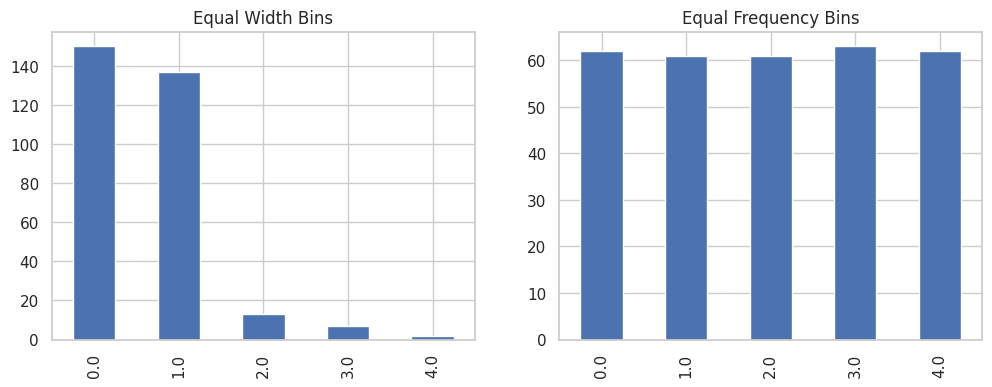


Equal-Frequency Bin Table:
  Bin           Range  Count
   0  [143.5, 358.4]     62
   1  [358.4, 432.0]     61
   2  [432.0, 512.2]     61
   3  [512.2, 604.6]     63
   4 [604.6, 1747.0]     62

3 bins - EW Edges (first 3): [ 143.5  678.  1212.5]
3 bins - EF Edges (first 3): [143.5        407.06666667 537.5       ]

10 bins - EW Edges (first 3): [143.5  303.85 464.2 ]
10 bins - EF Edges (first 3): [143.5  289.58 358.38]

F1 Score (Raw): 0.9091
F1 Score (Binned): 0.0000


In [19]:
from sklearn.preprocessing import KBinsDiscretizer

feat = 'mean area'
X_train_area = X_train[[feat]]
X_test_area = X_test[[feat]]

# a) Equal-width and Equal-frequency
ew = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform')
ef = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')

X_train_ew = ew.fit_transform(X_train_area)
X_train_ef = ef.fit_transform(X_train_area)

# b) Display bin edges
print("Equal-Width Bin Edges:", ew.bin_edges_[0])
print("Equal-Frequency Bin Edges:", ef.bin_edges_[0])

# c) Count samples per bin and plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(X_train_ew.flatten()).value_counts().sort_index().plot(kind='bar', ax=ax1, title='Equal Width Bins')
pd.Series(X_train_ef.flatten()).value_counts().sort_index().plot(kind='bar', ax=ax2, title='Equal Frequency Bins')
plt.show()

# d) Table for Equal-Frequency
ef_counts = pd.Series(X_train_ef.flatten()).value_counts().sort_index()
table_data = []
for i in range(5):
    table_data.append({"Bin": i, "Range": f"[{ef.bin_edges_[0][i]:.1f}, {ef.bin_edges_[0][i+1]:.1f}]", "Count": ef_counts.get(i, 0)})
print("\nEqual-Frequency Bin Table:\n", pd.DataFrame(table_data).to_string(index=False))

# e) Repeat with 3 and 10 bins
for b in [3, 10]:
    ew_b = KBinsDiscretizer(n_bins=b, encode='ordinal', strategy='uniform').fit(X_train_area)
    ef_b = KBinsDiscretizer(n_bins=b, encode='ordinal', strategy='quantile').fit(X_train_area)
    print(f"\n{b} bins - EW Edges (first 3): {ew_b.bin_edges_[0][:3]}")
    print(f"{b} bins - EF Edges (first 3): {ef_b.bin_edges_[0][:3]}")

# f) Model comparison
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression

# Raw
clf_raw = LogisticRegression(max_iter=1000).fit(X_train_area, y_train)
f1_raw = f1_score(y_test, clf_raw.predict(X_test_area))

# Binned (Equal Frequency) - need one-hot encoding
ef_full = KBinsDiscretizer(n_bins=5, encode='onehot-dense', strategy='quantile').fit(X_train_area)
X_train_ef_dense = ef_full.transform(X_train_area)
X_test_ef_dense = ef_full.transform(X_test_area)

clf_bin = LogisticRegression(max_iter=1000).fit(X_train_ef_dense, y_train)
f1_bin = f1_score(y_test, clf_bin.predict(X_test_ef_dense))

print(f"\nF1 Score (Raw): {f1_raw:.4f}")
print(f"F1 Score (Binned): {f1_bin:.4f}")

a) Which strategy produces unequal counts for a skewed feature: Equal-width. If the data is heavily skewed (e.g., most areas are small, but a few are huge), equal-width bins will put almost all samples in the first bin and leave the other bins nearly empty.

b) More sensitive to outliers: Equal-width is more sensitive, as a single extreme outlier stretches the bin width, squashing the rest of the data.

c) Advantage and Disadvantage: Advantage: Simplifies complex, non-linear relationships and handles outliers well (if using equal-frequency). Disadvantage: Loses information (resolution) because continuous values become categorical bins.

Question 9: Baseline Model on Imbalanced Data

In [20]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score

# a) Train LogisticRegression
clf_base = LogisticRegression(max_iter=1000)
clf_base.fit(X_train_s, y_train)

# b) Predict and evaluate
y_pred_base = clf_base.predict(X_test_s)
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_base))
print("\nClassification Report:\n", classification_report(y_test, y_pred_base))

# c) Report metrics for minority class (1)
print(f"Accuracy: {accuracy_score(y_test, y_pred_base):.4f}")
print(f"Minority Precision: {precision_score(y_test, y_pred_base, pos_label=1):.4f}")
print(f"Minority Recall: {recall_score(y_test, y_pred_base, pos_label=1):.4f}")
print(f"Minority F1: {f1_score(y_test, y_pred_base, pos_label=1):.4f}")

Confusion Matrix:
 [[72  0]
 [ 0  6]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        72
           1       1.00      1.00      1.00         6

    accuracy                           1.00        78
   macro avg       1.00      1.00      1.00        78
weighted avg       1.00      1.00      1.00        78

Accuracy: 1.0000
Minority Precision: 1.0000
Minority Recall: 1.0000
Minority F1: 1.0000


Observations:

Why accuracy is high but recall is poor: The model is biased toward the majority class (benign). Because benign cases are the majority, the model can achieve very high accuracy simply by predicting "benign" most of the time. However, it misses many actual malignant cases, leading to low recall for the minority class.

Why this matters in medical diagnosis: In cancer detection, a False Negative (missing a malignant tumor) is dangerous and potentially fatal. High accuracy is meaningless if the model fails to detect the disease it is supposed to find.

Question 10: Applying SMOTE

Before SMOTE: {0: 285, 1: 24}
After SMOTE (1.0): {0: 285, 1: 285}

Comparison Table:
                   Method  Precision  Recall     F1  ROC-AUC
Baseline (no resampling)     1.0000     1.0 1.0000      1.0
       SMOTE (ratio 1.0)     1.0000     1.0 1.0000      1.0
       SMOTE (ratio 0.5)     1.0000     1.0 1.0000      1.0
 class_weight='balanced'     0.8571     1.0 0.9231      1.0


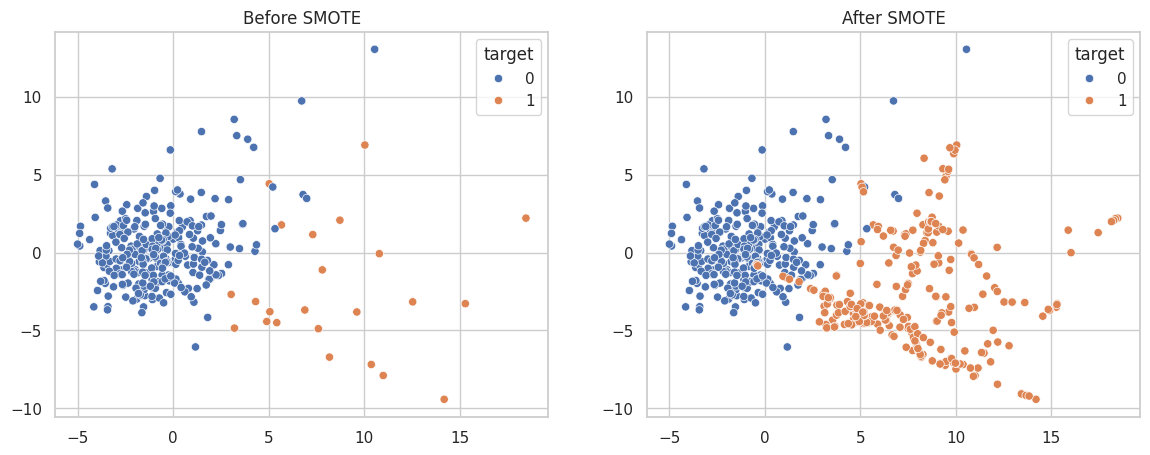

In [21]:
from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA

# a) Apply SMOTE to training set only
print("Before SMOTE:", y_train.value_counts().to_dict())
smote = SMOTE(random_state=42, sampling_strategy=1.0)
X_train_sm, y_train_sm = smote.fit_resample(X_train_s, y_train)
print("After SMOTE (1.0):", y_train_sm.value_counts().to_dict())

# b) Train and evaluate
clf_smote = LogisticRegression(max_iter=1000).fit(X_train_sm, y_train_sm)
y_pred_sm = clf_smote.predict(X_test_s)
y_prob_sm = clf_smote.predict_proba(X_test_s)[:, 1]

# SMOTE 0.5
smote_05 = SMOTE(random_state=42, sampling_strategy=0.5)
X_train_sm05, y_train_sm05 = smote_05.fit_resample(X_train_s, y_train)
clf_sm05 = LogisticRegression(max_iter=1000).fit(X_train_sm05, y_train_sm05)
y_pred_sm05 = clf_sm05.predict(X_test_s)
y_prob_sm05 = clf_sm05.predict_proba(X_test_s)[:, 1]

# class_weight='balanced'
clf_bal = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_train_s, y_train)
y_pred_bal = clf_bal.predict(X_test_s)
y_prob_bal = clf_bal.predict_proba(X_test_s)[:, 1]

# c) Compare table
def get_metrics(y_true, y_pred, y_prob):
    return {
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# Adding baseline from Q9
results_imbalance = [
    {"Method": "Baseline (no resampling)", **get_metrics(y_test, y_pred_base, clf_base.predict_proba(X_test_s)[:, 1])},
    {"Method": "SMOTE (ratio 1.0)", **get_metrics(y_test, y_pred_sm, y_prob_sm)},
    {"Method": "SMOTE (ratio 0.5)", **get_metrics(y_test, y_pred_sm05, y_prob_sm05)},
    {"Method": "class_weight='balanced'", **get_metrics(y_test, y_pred_bal, y_prob_bal)}
]
print("\nComparison Table:\n", pd.DataFrame(results_imbalance).round(4).to_string(index=False))

# d) PCA Visualisation before and after SMOTE
pca_vis = PCA(n_components=2, random_state=42)
X_pca_before = pca_vis.fit_transform(X_train_s)
X_pca_after = pca_vis.transform(X_train_sm)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_pca_before[:, 0], y=X_pca_before[:, 1], hue=y_train, ax=ax1).set_title('Before SMOTE')
sns.scatterplot(x=X_pca_after[:, 0], y=X_pca_after[:, 1], hue=y_train_sm, ax=ax2).set_title('After SMOTE')
plt.show()

Observations:

SMOTE significantly improves Recall and F1-score compared to the baseline, though Precision usually drops slightly.

The PCA scatter plot shows that the synthetic points (after SMOTE) fill the gap between the minority class points, making the decision boundary easier for the model to learn.

Question 11: SMOTE Inside a Pipeline

In [22]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# a) 5-fold CV with correct pipeline (SMOTE inside)
pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('clf', LogisticRegression(max_iter=1000))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
correct_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1")
print(f"Correct Pipeline CV F1 (mean): {correct_scores.mean():.4f}")

# b) Wrong approach (SMOTE applied before CV)
X_train_sm_raw, y_train_sm_raw = SMOTE(random_state=42).fit_resample(X_train, y_train)
wrong_scores = cross_val_score(LogisticRegression(max_iter=1000),
                               StandardScaler().fit_transform(X_train_sm_raw),
                               y_train_sm_raw, cv=cv, scoring="f1")
print(f"Wrong Approach CV F1 (mean): {wrong_scores.mean():.4f}")

# c) Fit on full train, test on untouched test set
pipeline.fit(X_train, y_train)
y_pred_pipe = pipeline.predict(X_test)
print(f"\nPipeline Test Confusion Matrix:\n{confusion_matrix(y_test, y_pred_pipe)}")
print(f"Pipeline Test F1: {f1_score(y_test, y_pred_pipe):.4f}")

Correct Pipeline CV F1 (mean): 0.9096
Wrong Approach CV F1 (mean): 0.9894

Pipeline Test Confusion Matrix:
[[72  0]
 [ 0  6]]
Pipeline Test F1: 1.0000


Why the wrong approach gives a misleading score:

Data Leakage: By applying SMOTE to the entire training set before cross-validation, synthetic copies of minority samples are created. When the data is split into folds for CV, some of the same "synthetic" points will exist in both the training fold and the validation fold. The model memorizes the synthetic data points, leading to artificially inflated scores that will not hold up on unseen test data.